<a href="https://colab.research.google.com/github/boscof0715-commits/AI-soc/blob/main/linear_regression_notebook_tutorial_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Session 1: Linear Regression - Hands-on Exercises



In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(22)
plt.rcParams.update({"figure.figsize": (6, 4), "axes.grid": True, "grid.alpha": 0.3})

## 1. Generate data and split it

We create data from a known rule, $y = 2x + 1 + \text{noise}$, so we can check whether the model recovers it.
Then we split into a **train** set (fit the parameters) and a **test** set (judge the performance).

[3.66346915 1.99295379 0.88558373 6.53191688 4.59337045 9.87675619
 8.5156807  8.36961323 0.51438767 5.55345155 6.07464526 0.50141295
 4.77327953 3.29563809 2.16485682 7.97016733 4.2089889  1.03183109
 3.69070619 9.14844427 3.89597155 1.87335859 0.66736155 5.12171558
 6.67555985 4.12809584 8.48319404 5.24489063 7.97434308 5.65152404
 5.90798902 4.12496577 1.09720159 7.04590288 8.58393427 7.2502816
 4.19565976 0.87107484 1.85789124 5.5126461  6.58849296 0.2637789
 9.42920042 7.14620214 7.22388542 9.88173914 6.20824101 4.92429754
 2.24403456 6.8524315 ]


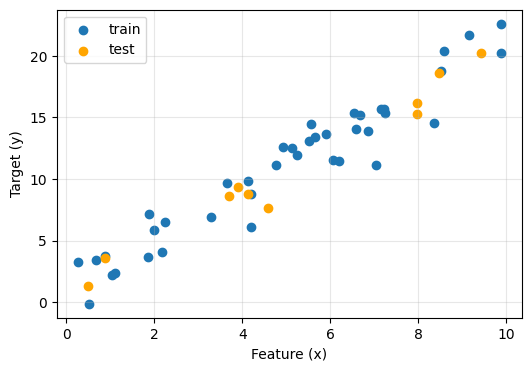

In [ ]:
n = 50
w_true, b_true = 2.0, 1.0
# choosing random x values between 0, 10
x = rng.uniform(0, 10, n)
print(x)
# making the line
y = w_true * x + b_true + rng.normal(0, 1.5, n) # adding some noise (gotta make life annoying for ourselves)

# using the first 40 values as training, last 40-50 as the testing data
idx = rng.permutation(n)
train, test = idx[:40], idx[40:]
x_tr, y_tr = x[train], y[train]
x_te, y_te = x[test],  y[test]

#plotting it
plt.scatter(x_tr, y_tr, label="train")
plt.scatter(x_te, y_te, color="orange", label="test")
plt.xlabel("Feature (x)"); plt.ylabel("Target (y)"); plt.legend(); plt.show()

## 2. Predict a number: guess a line

The model is $\hat y = wx + b$, where $w$ is the slope and $b$ is the baseline (intercept).

**Exercise 2.** Change `w` and `b` below until the line looks like a good fit by eye.
Try the flat line $w=0,\ b=10$ from the slides first.

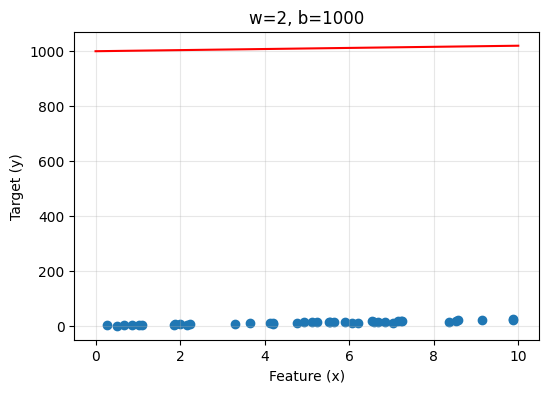

In [ ]:
def predict(x, w, b):
  return w*x + b

w, b = 2, 1000 # try change these around and find the best parameters by hand

xs = np.linspace(0, 10, 100)
plt.scatter(x_tr, y_tr)
plt.plot(xs, predict(xs, w, b), "r")
plt.xlabel("Feature (x)"); plt.ylabel("Target (y)"); plt.title(f"w={w}, b={b}"); plt.show()

## 3. Least squares loss

The **residual** is the actual value minus the prediction: $e_i = y_i - \hat y_i$.
Squaring stops positive and negative errors cancelling, and we average them:

$$L(w,b) = \frac{1}{2n}\sum_{i=1}^{n}\left(y_i - \hat y_i\right)^2$$

In [ ]:
def loss(w, b, x, y):
    residuals = y - predict(x,w,b)
    res = np.mean(residuals ** 2) / 2
    return res

for (w_, b_) in [(0, 10), (1, 0), (2, 1), (3, 5)]:
    print(f"w={w_}, b={b_}:  loss = {loss(w_, b_, x_tr, y_tr):.2f}")

w=0, b=10:  loss = 16.95
w=1, b=0:  loss = 23.87
w=2, b=1:  loss = 1.24
w=3, b=5:  loss = 43.57


**Exercise 3.** Which guess has the lowest loss? Does it match what you saw by eye in Section 2?

Now look at the loss for *every* pair $(w,b)$. It forms a **bowl**, and the lowest point is the best line.

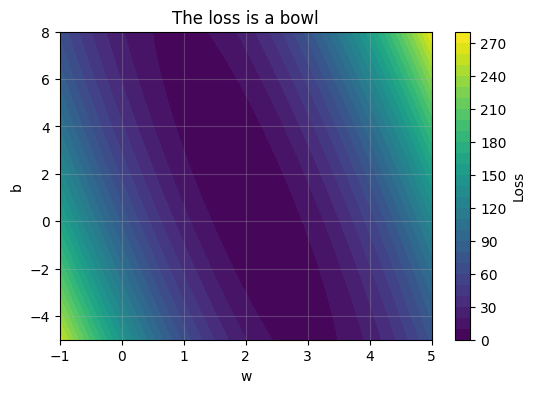

In [ ]:
W, B = np.meshgrid(np.linspace(-1, 5, 200), np.linspace(-5, 8, 200))
Z = np.array([[loss(wi, bi, x_tr, y_tr) for wi in W[0]] for bi in B[:, 0]])

plt.contourf(W, B, Z, levels=30, cmap="viridis")
plt.colorbar(label="Loss")
plt.xlabel("w"); plt.ylabel("b"); plt.title("The loss is a bowl"); plt.show()

## 4. Method 1: find the minimum directly (normal equations)

Set the gradient to zero. In matrix form, with $X$ = a column of $x$ values plus a column of ones:

$$\nabla_w L = 0 \;\Rightarrow\; w = (X^\top X)^{-1} X^\top y$$

Here $w$ holds both the slope and the intercept.

In [ ]:
X_tr = np.column_stack([x_tr, np.ones_like(x_tr)])
# linalg.solve solves for w in the form aw = b
theta = np.linalg.solve(X_tr.T @ X_tr, X_tr.T @ y_tr)
w_ne, b_ne = theta
print(f"Normal equations:  w = {w_ne:.4f}, b = {b_ne:.4f}   (truth: w=2, b=1)")

Normal equations:  w = 2.0211, b = 1.0553   (truth: w=2, b=1)


**Exercise 4.** Re-run Sections 1 and 4 with `n = 10`, then `n = 500`. How close do $w$ and $b$ get to the truth, and why?

## 5. Method 2: gradient descent

Instead of solving in one step, repeatedly step downhill:

$$w \leftarrow w - \eta\,\frac{\partial L}{\partial w}, \qquad b \leftarrow b - \eta\,\frac{\partial L}{\partial b}$$

with

$$\frac{\partial L}{\partial w} = -\frac{2}{n}\sum x_i\,(y_i-\hat y_i), \qquad \frac{\partial L}{\partial b} = -\frac{2}{n}\sum (y_i-\hat y_i)$$

$\eta$ (eta) is the **learning rate**. We stop when the loss barely changes (`tol`) or after `max_iter` steps.

In [ ]:
def gradient_descent(x, y, eta=0.01, max_iter=5000, tol=1e-9, w0=0.0, b0=0.0):
    w, b = w0, b0
    n = len(x)
    history = [(w, b, loss(w, b, x, y))]
    for k in range(max_iter):
        e = y - predict(x, w, b)
        dw = - (2/n) * np.sum(x* e)
        db = - (2/n) * np.sum(e)
        w = w - eta * dw
        b = b - eta * db
        history.append((w, b, loss(w, b, x, y)))
        if abs(history[-2][2] - history[-1][2]) < tol: # cutoff: loss stopped improving
            break
    return w, b, np.array(history)

w_gd, b_gd, hist = gradient_descent(x_tr, y_tr, eta=0.01)
print(f"Stopped after {len(hist)-1} steps")
print(f"Gradient descent:  w = {w_gd:.4f}, b = {b_gd:.4f}")
print(f"Normal equations:  w = {w_ne:.4f}, b = {b_ne:.4f}")

Stopped after 1463 steps
Gradient descent:  w = 2.0212, b = 1.0544
Normal equations:  w = 2.0211, b = 1.0553


**Exercise 5.** Change `tol` to `1e-3`, then `1e-12`. How many steps does it take each time, and how far from the normal-equation answer do you end up? This is the trade-off in choosing a cutoff: a loose cutoff stops early with a mostly right answer.

## 6. The learning rate

Too small and it crawls; too large and it overshoots. Compare four values of $\eta$.

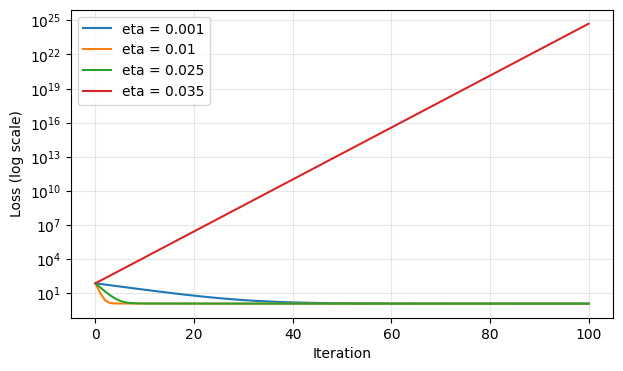

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
for eta in [0.001, 0.01, 0.025, 0.035]:
    _, _, h = gradient_descent(x_tr, y_tr, eta=eta, max_iter=100, tol=0)
    ax.plot(h[:, 2], label=f"eta = {eta}")
ax.set_yscale("log"); ax.set_xlabel("Iteration"); ax.set_ylabel("Loss (log scale)")
ax.legend(); plt.show()

**Exercise 6.** Which values converge (work)?
